# Invisible Warriors
26.04.2026

## Data Preparation

V4, using section_column_scales.tsv (instead of section_columns.tsv) of before

V5, removing from this notebook and moving to the feature engineering notebook (EDA_and_FeatureEngineering.ipynb): 
- feature section allocation (from external file)
- imputation of the missing values for days since october 7th
- remove meta data columns and export to a metadata df

V6, 
- for the section definition, use column names instead of column indices (this is more robust to changes in input format)
- use section_column_names_scale
- depend on attestation_timestamp and leave NA if is empty
- when parsing time to minutes, defaultly assume minutes, even for the small numbers


IMPORTANT! this notebook cleans up the data of only the completely useless parameters, e.g. fake participants, all empty columns.
Any data with more nuance, such as not all empty columns but still with a high % of missing data, or "real" participants
but that are still outliers, will be handled later on, in the feature processing and in the modeling dections.
So sometimes it might seem like there are redundancies, for example the filtering of the empty features. But it is a
design necessity, given the different uses for this data (Avital's needs, taking all features into account, and as many of the participants),
and modeling needs. 

V7 (25.05.2026)
- outsource all of the functions to "code\functions.py"
- removed some QC parameters that werent helpful

In [1]:
# ============================================================
# 1. SETUP AND CONFIGURATION
# ============================================================
# This block defines:
# - File paths
# - Output directories
# - Logging system
# - Plot saving functions
# - Global plotting style
#
# This ensures full reproducibility and clean workflow.
# ============================================================

import os
import sys
from pathlib import Path
from datetime import datetime
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath(".."))
from functions import *

# Create timestamp for reproducible versioned outputs
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M")
dir_timestamp = datetime.now().strftime("%Y%m%d%H%M")
# ------------------------------------------------------------
# Define paths
# ------------------------------------------------------------

# Try script path first (if running as .py)
if "__file__" in globals():
    CODE_PATH = os.path.abspath(__file__)
else:
    # Fallback for notebooks (manual, robust approach)
    CODE_PATH = os.path.abspath("01.dataset_preparation.ipynb")

DATA_DIR = Path(r"C:\Users\NoaBarLiss\OneDrive\Documents\02.Personal_development\invisible_warriors\data")

DATA_PATH = DATA_DIR / "raw_data.xlsx"

DUPLICATES_DF_PATH = DATA_DIR / "duplicates_to_drop.xlsx"

# base directory
BASE_DIR = Path(r"HOME_PATH\code\00.Data_prep\outputs")

# full directory with timestamp
OUTPUT_DIR = BASE_DIR / dir_timestamp

LOG_PATH = OUTPUT_DIR / "log.txt"

# Create outputs directory if it does not exist
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Output directory set to:\n{OUTPUT_DIR}")

write_log("Loading duplicate participant table.", LOG_PATH)

duplicates_df = pd.read_excel(DUPLICATES_DF_PATH)

# Keep only required columns
duplicates_df = duplicates_df[
    ["record_id", "reason"]
].copy()

# Convert to lookup dictionary
duplicate_reason_map = dict(
    zip(
        duplicates_df["record_id"],
        duplicates_df["reason"]
    )
)

Output directory set to:
C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624
[2026-06-07 16:24:55] Loading duplicate participant table.


In [2]:
## Configuration

# Initialize log file if new
if not LOG_PATH.exists():
    write_log(f"Session timestamp: {TIMESTAMP}", LOG_PATH)
    write_log(f"Running on data from: {DATA_PATH}", LOG_PATH)
    write_log("Log file created.", LOG_PATH)
    write_log("Data preparation started.", LOG_PATH)
    write_log(f"Output directory set to:\n{OUTPUT_DIR}", LOG_PATH)

# ============================================================
# Global plotting style — conference quality
# ============================================================

sns.set_theme(
    style="whitegrid",
    context="talk",   # larger fonts suitable for presentations
)

plt.rcParams["figure.figsize"] = (8, 6)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelweight"] = "bold"
plt.rcParams["figure.dpi"] = 120

write_log("Plotting style configured.", LOG_PATH)

# ============================================================
# GLOBAL FEATURE REMOVAL AUDIT OBJECTS
# ============================================================
# Output Excel path
FEATURE_REMOVAL_AUDIT_PATH = (OUTPUT_DIR / "feature_removal_audit.xlsx")
FEATURE_REMOVAL_LOG_PATH = (OUTPUT_DIR / "feature_removal_log.xlsx")

# FEATURE REMOVAL REGISTRY
feature_removal_registry = []

# Initialize in-memory audit tables
# IMPORTANT: These persist across notebook execution

if "removed_feature_values_df" not in globals():
    removed_feature_values_df = pd.DataFrame()

if "removal_log_df" not in globals():
    removal_log_df = pd.DataFrame()


[2026-06-07 16:24:55] Plotting style configured.


In [3]:
# ============================================
# 2. Load dataset safely
# ============================================

# REDCAP begines the headers at second row
df_raw = pd.read_excel(DATA_PATH, header=1)

# Create working copy
df = df_raw.copy()

write_log(f"Dataset loaded successfully", LOG_PATH)
write_log(f"Shape: {df.shape}", LOG_PATH)

display(df.head())

# ============================================
# Structural audit
# ============================================

audit_summary = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100,
    "n_unique": df.nunique(dropna=True)
})

audit_summary = audit_summary.sort_values("missing_percent", ascending=False)

display(audit_summary)

audit_summary.to_csv(OUTPUT_DIR / "audit_variable_summary.csv", index=False)

write_log("Structural audit completed", LOG_PATH)

[2026-06-07 16:24:56] Dataset loaded successfully
[2026-06-07 16:24:56] Shape: (526, 372)


,record_id,redcap_event_name,redcap_survey_identifier,attestation_timestamp,receive_communication,inclusion,exclusion,agree,interview_consent,contact_6mn,...,ptg_relating_others,ptg_new_possibilities,ptg_personal_strength,ptg_spiritual,ptg_life_appreciation,wants_intervention,posttraumatic_growth_complete,feedback_timestamp,feedback,feedback_complete
0,1,baseline_arm_1,NaN,2025-10-22 07:03:15,NaN,1.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,0
1,2,baseline_arm_1,NaN,2025-10-22 07:25:29,NaN,1.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,0
2,3,baseline_arm_1,NaN,2025-10-22 23:55:27,NaN,1.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,0
3,4,baseline_arm_1,NaN,2025-10-23 00:22:25,NaN,1.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,0
4,6,baseline_arm_1,NaN,2025-10-25 09:42:40,NaN,1.0,1.0,1.0,1.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,2,NaN,NaN,0


,column,dtype,n_missing,missing_percent,n_unique
abortion_5,abortion_5,float64,526,100.0,0
preg4_depression,preg4_depression,float64,526,100.0,0
preg_out_6,preg_out_6,float64,526,100.0,0
why_2,why_2,float64,526,100.0,0
preg_num_2,preg_num_2,float64,526,100.0,0
...,...,...,...,...,...
support_complete,support_complete,int64,0,0.0,2
psychological_complete,psychological_complete,int64,0,0.0,2
redcap_event_name,redcap_event_name,object,0,0.0,2
media_complete,media_complete,int64,0,0.0,2


[2026-06-07 16:24:56] Structural audit completed


In [4]:
# =======================================================================
# 2.1 Build subsection + section dictionary from section file
# (schema-preserving, auto-complete unmapped features)
# =======================================================================

write_log("Loading subsection definitions.", LOG_PATH)

SECTION_FILE = DATA_DIR / "section_column_names_scales.tsv"
sections_df = pd.read_csv(SECTION_FILE, sep="\t")

write_log(f"Section definition file loaded. Rows: {len(sections_df)}", LOG_PATH)
display(sections_df)

# -------------------------------------------------------------------
# Keep only rows whose feature exists in df
# This preserves the original schema exactly as defined in SECTION_FILE
# while dropping stale mappings for features no longer present in df.
# -------------------------------------------------------------------
write_log("Filtering section definitions to features present in df.", LOG_PATH)

sections_df = sections_df.loc[
    sections_df["column_name"].isin(df.columns)
].copy()

write_log(f"Valid section rows retained: {len(sections_df)}", LOG_PATH)

# -------------------------------------------------------------------
# Auto-add unmapped df features
# Any feature present in df but absent from the section file is appended
# as section='unmapped', subsection='unmapped', while preserving the full
# original schema of sections_df (all other metadata columns stay intact).
# -------------------------------------------------------------------
mapped_cols = set(sections_df["column_name"])
unmapped_cols = [col for col in df.columns if col not in mapped_cols]

if unmapped_cols:
    unmapped_rows = pd.DataFrame(columns=sections_df.columns)
    unmapped_rows["column_name"] = unmapped_cols
    unmapped_rows["section"] = "unmapped"
    unmapped_rows["subsection"] = "unmapped"

    sections_df = pd.concat([sections_df, unmapped_rows], ignore_index=True)

write_log(f"Unmapped features auto-added: {len(unmapped_cols)}", LOG_PATH)

# -------------------------------------------------------------------
# Validate uniqueness
# After auto-completion, every df feature should appear exactly once in
# sections_df. Duplicate assignments indicate a broken section file.
# -------------------------------------------------------------------
dup_count = sections_df["column_name"].duplicated().sum()
if dup_count > 0:
    dup_cols = sections_df.loc[
        sections_df["column_name"].duplicated(), "column_name"
    ].tolist()
    raise ValueError(
        f"Duplicate column assignments across subsections: {dup_count} "
        f"({', '.join(dup_cols)})"
    )

write_log("Subsection uniqueness validation passed.", LOG_PATH)

# -------------------------------------------------------------------
# Build dictionaries from canonical section table
# sections_df is now the complete source of truth for all df features.
# -------------------------------------------------------------------
subsection_dict = (
    sections_df
    .groupby("subsection", sort=False)["column_name"]
    .apply(list)
    .to_dict()
)

section_dict = (
    sections_df
    .groupby("section", sort=False)["column_name"]
    .apply(list)
    .to_dict()
)

write_log("Subsection and section dictionaries created.", LOG_PATH)
write_log(f"Total subsections: {len(subsection_dict)}", LOG_PATH)
write_log(f"Total sections: {len(section_dict)}", LOG_PATH)

for k, v in subsection_dict.items():
    write_log(f"Subsection {k}: {len(v)} columns", LOG_PATH)

for k, v in section_dict.items():
    write_log(f"Section {k}: {len(v)} columns", LOG_PATH)

# -------------------------------------------------------------------
# Export long-format mapping
# sections_df is already long-format (one row per feature), so export a
# schema-preserving copy and add helper columns only at export time.
# -------------------------------------------------------------------
long_df = sections_df.copy()

# Add subsection size as a convenience field for downstream inspection.
long_df["n_columns"] = long_df.groupby("subsection")["column_name"].transform("count")

long_df.to_csv(
    OUTPUT_DIR / "section_column_names_scales.tsv",
    sep="\t",
    index=False
)

write_log("Long-format subsection-column mapping exported.", LOG_PATH)

# -------------------------------------------------------------------
# Subsection audit summary
# -------------------------------------------------------------------
subsection_audit = (
    sections_df
    .groupby(["subsection", "section"], sort=False)
    .agg(
        n_columns=("column_name", "count"),
        column_names=("column_name", ", ".join)
    )
    .reset_index()
)

subsection_audit.to_csv(
    OUTPUT_DIR / "subsection_dictionary_summary.csv",
    index=False
)

write_log("Subsection dictionary summary exported.", LOG_PATH)

# -------------------------------------------------------------------
# Section audit summary
# -------------------------------------------------------------------
section_audit = (
    sections_df
    .groupby("section", sort=False)
    .agg(
        n_columns=("column_name", "count"),
        column_names=("column_name", ", ".join)
    )
    .reset_index()
)

section_audit.to_csv(
    OUTPUT_DIR / "section_dictionary_summary.csv",
    index=False
)

write_log("Section dictionary summary exported.", LOG_PATH)

# -------------------------------------------------------------------
# Reconciliation summary
# After auto-completion, df_not_in_dict should always be zero unless
# something failed upstream.
# -------------------------------------------------------------------
dict_cols = sorted(sections_df["column_name"].unique().tolist())
df_cols = sorted(df.columns.tolist())

dict_not_in_df = sorted(set(dict_cols) - set(df_cols))
df_not_in_dict = sorted(set(df_cols) - set(dict_cols))

write_log("Column reconciliation summary:", LOG_PATH)

write_log(f"Columns in dictionary but missing from df: {len(dict_not_in_df)}", LOG_PATH)
if dict_not_in_df:
    write_log("Missing from df: " + ", ".join(dict_not_in_df), LOG_PATH)

write_log(f"Columns in df but missing from dictionary: {len(df_not_in_dict)}", LOG_PATH)
if df_not_in_dict:
    write_log("Missing from dictionary: " + ", ".join(df_not_in_dict), LOG_PATH)

[2026-06-07 16:24:56] Loading subsection definitions.
[2026-06-07 16:24:56] Section definition file loaded. Rows: 335


,subsection,section,n_columns,column_name,score_component,source
0,id,id,1,record_id,False,0
1,attestation,attestation,11,redcap_event_name,False,0
2,attestation,attestation,11,redcap_survey_identifier,False,0
3,attestation,attestation,11,attestation_timestamp,False,0
4,attestation,attestation,11,receive_communication,False,0
...,...,...,...,...,...,...
330,post_traumatic_growth_1,post_traumatic_growth,6,compassion,True,PTGI
331,post_traumatic_growth_1,post_traumatic_growth,6,relationships,True,PTGI
332,post_traumatic_growth_1,post_traumatic_growth,6,wonderful_ppl,True,PTGI
333,post_traumatic_growth_1,post_traumatic_growth,6,needing,True,PTGI


[2026-06-07 16:24:56] Filtering section definitions to features present in df.
[2026-06-07 16:24:56] Valid section rows retained: 333
[2026-06-07 16:24:56] Unmapped features auto-added: 39
[2026-06-07 16:24:56] Subsection uniqueness validation passed.
[2026-06-07 16:24:56] Subsection and section dictionaries created.
[2026-06-07 16:24:56] Total subsections: 44
[2026-06-07 16:24:56] Total sections: 19
[2026-06-07 16:24:56] Subsection id: 1 columns
[2026-06-07 16:24:56] Subsection attestation: 10 columns
[2026-06-07 16:24:56] Subsection partners_of_reservist_study: 2 columns
[2026-06-07 16:24:56] Subsection demographics: 4 columns
[2026-06-07 16:24:56] Subsection age: 1 columns
[2026-06-07 16:24:56] Subsection gender: 2 columns
[2026-06-07 16:24:56] Subsection religion: 2 columns
[2026-06-07 16:24:56] Subsection education: 1 columns
[2026-06-07 16:24:56] Subsection financial_security: 4 columns
[2026-06-07 16:24:56] Subsection income: 2 columns
[2026-06-07 16:24:56] Subsection prone_to_s

In [5]:
# ========================================
# ADD TEMPORAL FEATURE — TIME SINCE OCTOBER 7
# ========================================

write_log(
    "Add feature: time since October 7th.\n"
    "Processing timestamp and computing time delta.", 
    LOG_PATH
)

REFERENCE_DATE = pd.Timestamp("2023-10-07")

# ============================================================
# STEP 1 — PARSE TIMESTAMP
# ============================================================

# ------------------------------------------------------------
# Use attestation_timestamp only
# Invalid parsing -> NaT
# ------------------------------------------------------------
df["event_timestamp"] = pd.to_datetime(
    df["attestation_timestamp"],
    errors="coerce"
)

# ============================================================
# STEP 2 — TRACK TIMESTAMP SOURCE
# ============================================================

# ------------------------------------------------------------
# Initial timestamp provenance
# ------------------------------------------------------------
df["timestamp_source"] = np.where(
    df["event_timestamp"].notna(),
    "attestation",
    "missing"
)

# ============================================================
# STEP 3 — LOG TIMESTAMP STATUS
# ============================================================

total = len(df)

n_attestation = (df["timestamp_source"] == "attestation").sum()

n_missing_timestamp = (df["timestamp_source"] == "missing").sum()

write_log(
    f"Timestamp source — attestation: "
    f"{n_attestation} "
    f"({n_attestation / total:.2%})", 
    LOG_PATH
)

write_log(f"Timestamp source — missing: "
    f"{n_missing_timestamp} "
    f"({n_missing_timestamp / total:.2%})", 
    LOG_PATH)

# ============================================================
# STEP 4 — COMPUTE days_since_oct7
# ============================================================

# ------------------------------------------------------------
# If event_timestamp is missing -> result remains NaN
# ------------------------------------------------------------
df["days_since_oct7"] = (df["event_timestamp"] - REFERENCE_DATE).dt.days

# ------------------------------------------------------------
# Track source of days_since value
# ------------------------------------------------------------
df["days_since_source"] = (df["timestamp_source"])

# ============================================================
# STEP 5 — INITIAL QC FLAGS
# ============================================================
# ------------------------------------------------------------
# Missing values
# ------------------------------------------------------------
df["qc_days_since_missing"] = (df["days_since_oct7"].isna())

# ------------------------------------------------------------
# Negative values
# ------------------------------------------------------------
df["qc_days_since_negative"] = (df["days_since_oct7"].notna() & (df["days_since_oct7"] < 0))

# ------------------------------------------------------------
# Combined problematic mask
# ------------------------------------------------------------
mask_problem = (df["qc_days_since_missing"] | df["qc_days_since_negative"])

# ------------------------------------------------------------
# Logging
# ------------------------------------------------------------
n_missing_days = (df["qc_days_since_missing"].sum())

n_negative_days = (df["qc_days_since_negative"].sum())

n_problem = (mask_problem.sum())

write_log(f"days_since_oct7 — missing: "
    f"{n_missing_days} "
    f"({n_missing_days / total:.2%})", 
    LOG_PATH)

write_log(f"days_since_oct7 — negative: "
    f"{n_negative_days} "
    f"({n_negative_days / total:.2%})", 
    LOG_PATH)

write_log(f"days_since_oct7 — total problematic: "
    f"{n_problem}", 
    LOG_PATH)

# ============================================================
# STEP 6 — IMPUTE PROBLEMATIC VALUES
# ============================================================

write_log("Imputing problematic days_since_oct7 values "
          "using neighboring record_ids.", 
          LOG_PATH)

# ------------------------------------------------------------
# IMPORTANT ASSUMPTION:
# record_id approximately reflects survey chronology
# ------------------------------------------------------------
df = (df.sort_values("record_id").reset_index(drop=True))

# ============================================================
# PASS 1 — FORWARD FILL
# Use closest PREVIOUS valid value
# ============================================================

last_valid = None

for i in range(len(df)):
    val = df.loc[i, "days_since_oct7"]

    # --------------------------------------------------------
    # Valid value
    # --------------------------------------------------------
    if pd.notna(val) and val >= 0:
        last_valid = val

    # --------------------------------------------------------
    # Problematic value
    # --------------------------------------------------------
    else:
        if last_valid is not None:
            df.loc[i,"days_since_oct7"] = last_valid

            df.loc[i,"days_since_source"] = "imputed_previous_id"

# ============================================================
# PASS 2 — BACKWARD FILL
# ONLY for unresolved rows
# Typically only earliest record_ids
# ============================================================

next_valid = None

for i in range(len(df) - 1, -1, -1):
    val = df.loc[i, "days_since_oct7"]

    # --------------------------------------------------------
    # Valid value
    # --------------------------------------------------------
    if pd.notna(val) and val >= 0:
        next_valid = val

    # --------------------------------------------------------
    # Still unresolved
    # --------------------------------------------------------
    else:
        if next_valid is not None:
            df.loc[i,"days_since_oct7"] = next_valid
            df.loc[i,"days_since_source"] = "imputed_next_id"

# ============================================================
# STEP 7 — FINAL QC
# ============================================================

# ------------------------------------------------------------
# Recompute QC flags AFTER imputation
# ------------------------------------------------------------
df["qc_days_since_missing"] = (df["days_since_oct7"].isna())

df["qc_days_since_negative"] = (df["days_since_oct7"].notna() & (df["days_since_oct7"] < 0))

# ------------------------------------------------------------
# Final counts
# ------------------------------------------------------------
n_missing_final = (df["qc_days_since_missing"].sum())

n_negative_final = (df["qc_days_since_negative"].sum())

n_imputed_previous = (df["days_since_source"] == "imputed_previous_id").sum()

n_imputed_next = (df["days_since_source"] == "imputed_next_id").sum()

# ------------------------------------------------------------
# Logging
# ------------------------------------------------------------
write_log(f"Imputed using previous id: "
    f"{n_imputed_previous}", 
    LOG_PATH)

write_log(f"Imputed using next id: "
    f"{n_imputed_next}", 
    LOG_PATH)

write_log(f"Missing time delta values after patch: "
    f"{n_missing_final}", 
    LOG_PATH)

write_log(f"Negative time delta values after patch: "
    f"{n_negative_final}", 
    LOG_PATH)

write_log("days_since_oct7 feature completed.", LOG_PATH)

[2026-06-07 16:24:56] Add feature: time since October 7th.
Processing timestamp and computing time delta.
[2026-06-07 16:24:56] Timestamp source — attestation: 413 (78.52%)
[2026-06-07 16:24:56] Timestamp source — missing: 113 (21.48%)
[2026-06-07 16:24:56] days_since_oct7 — missing: 113 (21.48%)
[2026-06-07 16:24:56] days_since_oct7 — negative: 0 (0.00%)
[2026-06-07 16:24:56] days_since_oct7 — total problematic: 113
[2026-06-07 16:24:56] Imputing problematic days_since_oct7 values using neighboring record_ids.
[2026-06-07 16:24:56] Imputed using previous id: 113
[2026-06-07 16:24:56] Imputed using next id: 0
[2026-06-07 16:24:56] Missing time delta values after patch: 0
[2026-06-07 16:24:56] Negative time delta values after patch: 0
[2026-06-07 16:24:56] days_since_oct7 feature completed.


[2026-06-07 16:24:56] Plotting days_since_oct7 vs record_id for sanity check.
[2026-06-07 16:24:57] Plot saved: days_since_oct7_vs_record_id.png
Saved plot: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\days_since_oct7_vs_record_id.png


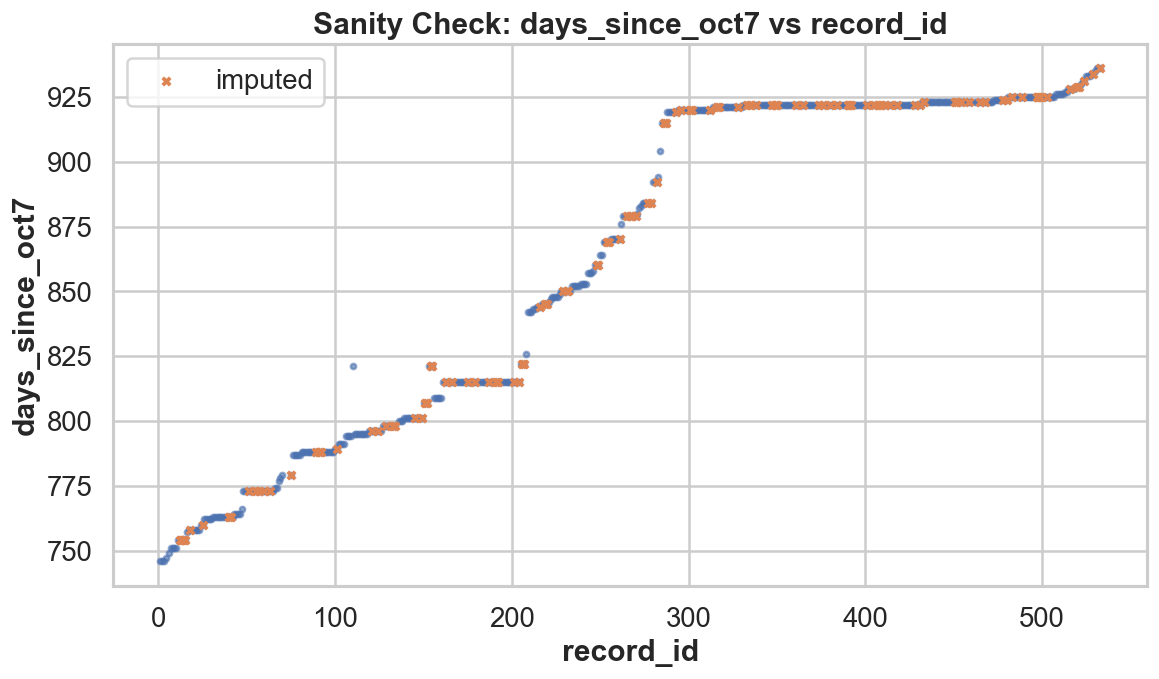

In [6]:
# ============================================================
# SANITY CHECK — DAYS SINCE OCT7 VS RECORD ID
# ============================================================

write_log("Plotting days_since_oct7 vs record_id for sanity check.", LOG_PATH)

# ------------------------------------------------------------
# Step 1 — Create figure
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6))

# ------------------------------------------------------------
# Step 2 — Base scatter
# ------------------------------------------------------------
ax.scatter(
    df["record_id"],
    df["days_since_oct7"],
    s=10,
    alpha=0.6
)

# ------------------------------------------------------------
# Step 3 — Highlight imputed points (if they exist)
# ------------------------------------------------------------
if "days_since_source" in df.columns:

    imputed_mask = df["days_since_source"] == "imputed_previous_id"

    ax.scatter(
        df.loc[imputed_mask, "record_id"],
        df.loc[imputed_mask, "days_since_oct7"],
        s=20,
        marker="x",
        label="imputed"
    )

# ------------------------------------------------------------
# Step 4 — Formatting
# ------------------------------------------------------------
ax.set_xlabel("record_id")
ax.set_ylabel("days_since_oct7")
ax.set_title("Sanity Check: days_since_oct7 vs record_id")

if "days_since_source" in df.columns:
    ax.legend()

ax.grid(True)
fig.tight_layout()

# ------------------------------------------------------------
# Step 5 — Save plot
# ------------------------------------------------------------
save_plot(fig, "days_since_oct7_vs_record_id", output_dir=OUTPUT_DIR, log_path=LOG_PATH)

plt.show()
plt.close()

cols_to_remove = "days_since_source"
# mark for removal
feature_removal_registry.append({
    "columns": cols_to_remove,
    "removal_reason": "temporary feature",
    "removal_stage": "days_since_oct7_calculation"
})

[2026-06-07 16:24:57] Creating missingness distribution plots.
[2026-06-07 16:24:57] Plot saved: missingness_per_variable.png
Saved plot: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\missingness_per_variable.png


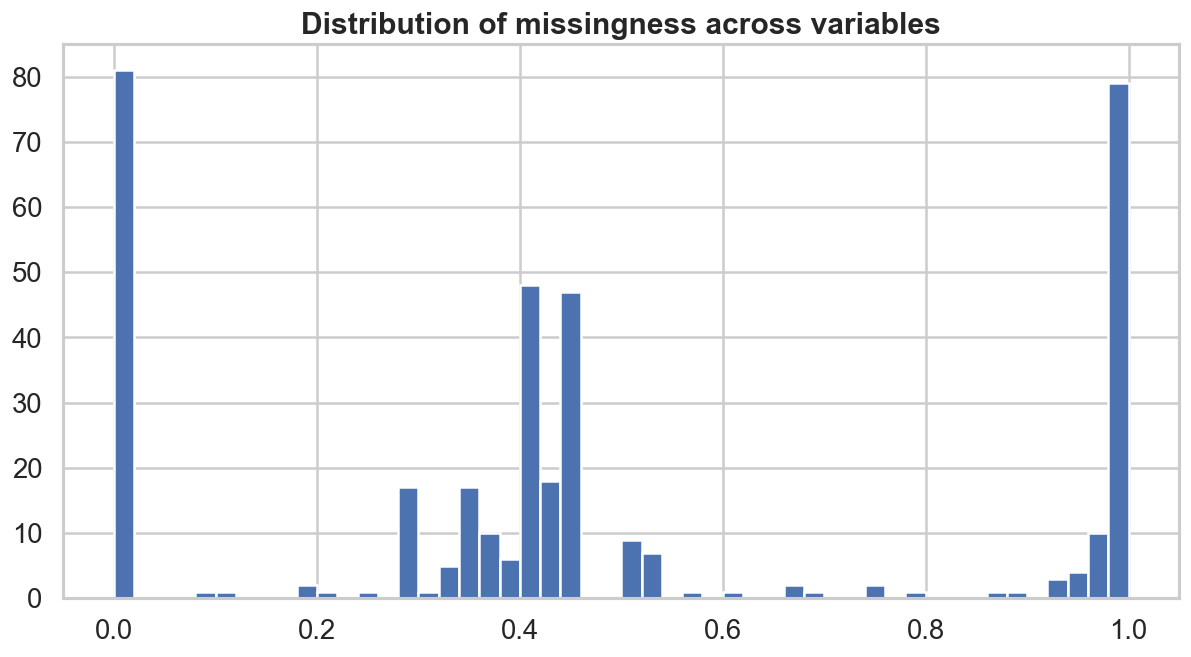

[2026-06-07 16:24:58] Plot saved: missing_summary.png
Saved plot: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\missing_summary.png


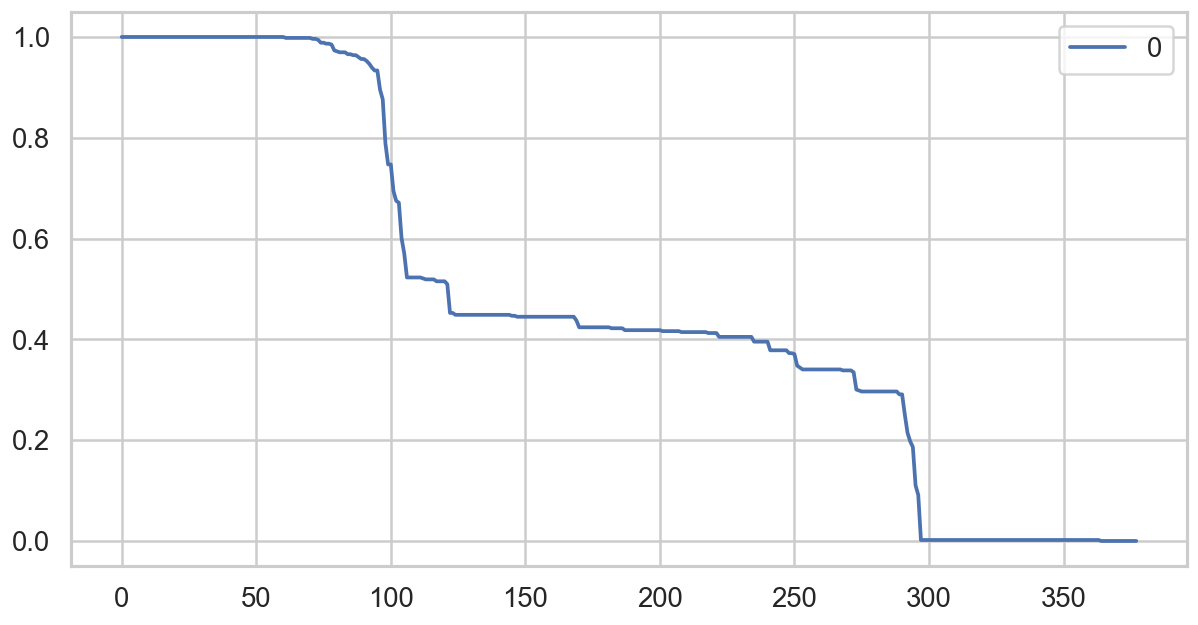

[2026-06-07 16:24:58] Variable missingness analysis complete


In [7]:
# ============================
# 5. Missingness per Feature
# ============================
missing_frac = df.isna().mean() 

# ------------------------------------------------------------
# Step 2 — Sort descending by missingness
# ------------------------------------------------------------
missing_summary = (missing_frac.sort_values(ascending=False).reset_index())

# Compute missingness only for analysis columns
missing_per_variable = (
    df
    .isna()
    .mean()
    .sort_values(ascending=False)
    .to_frame("missing_fraction")
)

write_log("Creating missingness distribution plots.", LOG_PATH)

#display(missing_per_variable.head())
missing_per_variable.to_csv(OUTPUT_DIR / "missingness_per_variable.csv")

fig, ax = plt.subplots(figsize=(12, 6))

missing_per_variable.hist(bins=50, ax=ax)

ax.set_title("Distribution of missingness across variables")

save_plot(fig=fig,
    filename="missingness_per_variable",
    output_dir=OUTPUT_DIR,
    log_path=LOG_PATH)

plt.show()


ax = missing_summary.plot(figsize=(12, 6))

fig = ax.get_figure()

save_plot(
    fig=fig,
    filename="missing_summary",
    output_dir=OUTPUT_DIR,
    log_path=LOG_PATH
)

plt.show()

write_log("Variable missingness analysis complete", LOG_PATH)

In [8]:
# ------------------------------------------------------------
# Identify variables with 100% missingness and Remove Them
# ------------------------------------------------------------

fully_missing_cols = missing_per_variable[
    missing_per_variable["missing_fraction"] == 1.0
].index.tolist()

write_log(f"Detected {len(fully_missing_cols)} columns with 100% missing values: {fully_missing_cols}", LOG_PATH)

# Save audit file
pd.Series(fully_missing_cols).to_csv(
    OUTPUT_DIR / "fully_missing_columns.csv",
    index=False
)


# mark features for removal
feature_removal_registry.append({
    "columns": fully_missing_cols,
    "removal_reason": "empty_features",
    "removal_stage": "calculate_missingness"
})

'''# Drop columns from dataframe
df = df.drop(columns=fully_missing_cols)'''

write_log(f"Marker fully missing columns for removal", LOG_PATH)

[2026-06-07 16:24:58] Detected 61 columns with 100% missing values: ['preg5_depression', 'preg_again', 'lac_mn4', 'preg_out_5', 'wk_delv5', 'abortion_5', 'breastfeed_y_n_5', 'lac_mn5', 'preg_num_2', 'preg_out_7', 'why_2', 'preg_out_6', 'preg6_depression', 'wk_delv6', 'abortion_6', 'combat_zone_2', 'breastfeed_y_n_4', 'abortion_4', 'wk_delv4', 'preg4_depression', 'preg_out_4', 'lac_mn3', 'breastfeed_y_n_3', 'abortion_3', 'wk_delv3', 'medical_and_psychiatric_history_6_months_later_complete', 'reservist_6_months_later_complete', 'worry_level_2', 'worry_change', 'reserv_days_2', 'status_6months', 'new_status', 'reserve_cur_2', 'lac_mn6', 'breastfeed_y_n_6', 'preg7_depression', 'hpt', 'redcap_survey_identifier', 'pcl5_c', 'nicu', 'blood_transfusion', 'pph', 'abruption', 'wk_delv7', 'sga', 'lbw', 'pprom', 'prom', 'apgar_at5', 'dm', 'preg8_depression', 'abortion_7', 'breastfeed_y_n_7', 'preg_complications', 'lac_mn7', 'preg_out_8', 'activ_combat_2', 'wk_delv8', 'lac_mn8', 'breastfeed_y_n_8', 

In [9]:
# =======================================================================
# 3. Separate the technical columns from the main DF
# =======================================================================
write_log("Starting separation of technical / non-useful REDCap columns.", LOG_PATH)

# ------------------------------------------------------------
# 1. Automatically detect timestamp columns (case-insensitive)
# ------------------------------------------------------------
timestamp_columns = [
    col for col in df.columns
    if "timestamp" in col.lower()
]

if timestamp_columns:
    write_log(f"*_timestamp columns marked for removal: {len(timestamp_columns)} \n{timestamp_columns}", LOG_PATH)

# ------------------------------------------------------------
# 2. Automatically detect section completion columns
# ------------------------------------------------------------
complete_columns = [
    col for col in df.columns
    if "complete" in col.lower()
]

if complete_columns:
    write_log(f"*_completed columns marked for removal: {len(complete_columns)} \n{complete_columns}", LOG_PATH)

section_columns_to_remove = []

# ------------------------------------------------------------
# 5. Remove derived / calculated variables that will be
#    recomputed later in the analysis pipeline
# ------------------------------------------------------------
derived_columns_to_remove = [
    "pcl5_c",
    "pcl5_cevillian_cutoff",
    "ptg_i_total",
    "ptg_i_categorization",
    "ptg_relating_others",
    "ptg_new_possibilities",
    "ptg_personal_strength",
    "ptg_spiritual",
    "ptg_life_appreciation"
]

write_log(f"Derived variables marked for removal: {len(derived_columns_to_remove)} \n{derived_columns_to_remove}", LOG_PATH)

# ------------------------------------------------------------
# 6. Combine all columns that should be separated
# ------------------------------------------------------------
technical_columns = list(
    set(
        timestamp_columns
        + complete_columns
        + section_columns_to_remove
        + derived_columns_to_remove
    )
)

# mark features for removal
feature_removal_registry.append({
    "columns": technical_columns,
    "removal_reason": "technical_features",
    "removal_stage": "separation_of_metadata"
})

# ------------------------------------------------------------
# Define columns that should be used for integrity checks
# (exclude columns that were marked for removal)
# ------------------------------------------------------------

analysis_columns = [
    col for col in df.columns
    if col not in technical_columns and col != "record_id"
]

[2026-06-07 16:24:58] Starting separation of technical / non-useful REDCap columns.
[2026-06-07 16:24:58] *_timestamp columns marked for removal: 17 
['attestation_timestamp', 'partners_of_reservists_study_timestamp', 'gen_timestamp', 'reserve_information_timestamp', 'media_timestamp', 'medical_and_psychiatric_history_timestamp', 'maternity_timestamp', 'adverse_childhood_experience_ace_questionnaire_timestamp', 'life_events_timestamp', 'psychological_timestamp', 'support_timestamp', 'ptsd_timestamp', 'gad_timestamp', 'posttraumatic_growth_timestamp', 'feedback_timestamp', 'event_timestamp', 'timestamp_source']
[2026-06-07 16:24:58] *_completed columns marked for removal: 18 
['attestation_complete', 'partners_of_reservists_study_complete', 'gen_complete', 'reserve_information_complete', 'reservist_6_months_later_complete', 'media_complete', 'medical_and_psychiatric_history_complete', 'medical_and_psychiatric_history_6_months_later_complete', 'maternity_complete', 'maternity_6_months_la

In [10]:
# ============================================
# 6. Global missingness characterization
# ============================================
analysis_columns = get_valid_analysis_columns(df, analysis_columns)

# Use only analysis-relevant columns
total_cells = df[analysis_columns].size
missing_cells = df[analysis_columns].isna().sum().sum()

missing_percent = missing_cells / total_cells * 100

write_log(f"Total cells: {total_cells}", LOG_PATH)
write_log(f"Missing cells: {missing_cells}", LOG_PATH)
write_log(f"Missing percent: {missing_percent:.2f}%", LOG_PATH)

[2026-06-07 16:24:58] Total cells: 175158
[2026-06-07 16:24:58] Missing cells: 86787
[2026-06-07 16:24:58] Missing percent: 49.55%


,missing_count,missing_percent
count,526.000000,526.000000
mean,164.994297,49.547837
std,78.719405,23.639461
min,87.000000,26.126126
25%,96.000000,28.828829
50%,103.000000,30.930931
75%,264.000000,79.279279
max,321.000000,96.396396


C:\Users\NoaBarLiss\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


[2026-06-07 16:24:58] Plot saved: missingness_per_participant.png
Saved plot: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\missingness_per_participant.png


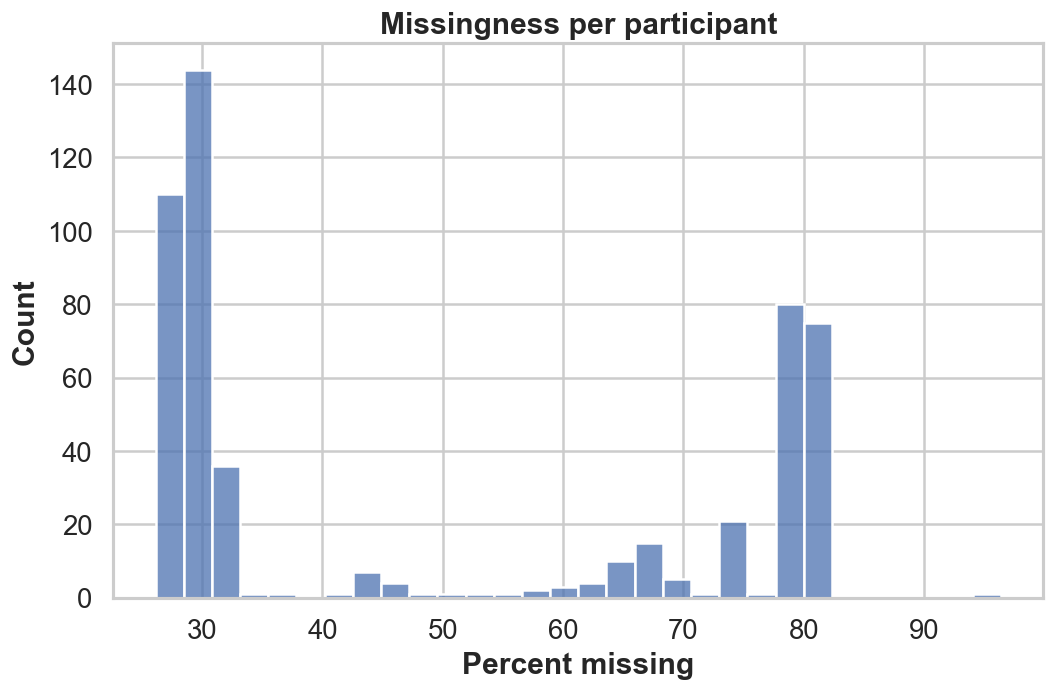

[2026-06-07 16:24:58] Participant missingness analysis complete


In [11]:
# ============================================
# 7. Missingness per participant
# ============================================
df["missing_count"] = df[analysis_columns].isna().sum(axis=1)
df["missing_percent"] = df[analysis_columns].isna().mean(axis=1) * 100

display(df[["missing_count", "missing_percent"]].describe())

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    df["missing_percent"],
    bins=30,
    ax=ax
)

ax.set_title("Missingness per participant")
ax.set_xlabel("Percent missing")
ax.set_ylabel("Count")

save_plot(
    fig=fig,
    filename="missingness_per_participant",
    output_dir=OUTPUT_DIR,
    log_path=LOG_PATH
)

plt.show()

write_log("Participant missingness analysis complete", LOG_PATH)

# Parse TEXT to NUMERIC in Problematic Features

In [12]:
# ============================================================
# APPLY PARSERS to time based features with textual values 
# ============================================================

import re
import numpy as np
import pandas as pd

write_log("Starting parsing pipeline for time-based features.", LOG_PATH)

TIME_MINUTES_CONFIG = {
    "type": "time_minutes",
    "allow_ranges": True,
    "allow_zero_words": True,
    "output_dtype": "Int64" 
}

TIME_WEEKS_CONFIG = {
    "type": "time_weeks",
    "allow_ranges": True,
    "output_dtype": "Int64"
}

TIME_YEARS_CONFIG = {
    "type": "time_years",
    "allow_ranges": True,
    "allow_zero_words": True,
    "output_dtype": "Int64"
}


# column: media_2wk
## Step 1 — run parser
df, change_df, review_path = run_parser_pre_manual(
    df,
    column="media_2wk",
    parser_func=parse_time_to_minutes,
    config=TIME_MINUTES_CONFIG,
    output_dir=OUTPUT_DIR,
    log_path=LOG_PATH
)
# 👉 manually edit the file here

## 26-4-26, i assumed the unit was minutes (even for small numbers) unless said otherwise

[2026-06-07 16:25:01] Starting parsing pipeline for time-based features.
[2026-06-07 16:25:01] Running parser for column: media_2wk
[2026-06-07 16:25:01] Manual review file exported: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\media_2wk_manual_review.csv
STOP! go over the file in: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\media_2wk_manual_review.csv
See if you want to make manual adjustments. If so, make them, save and exit and come back here to run the next block


In [13]:
# column: media_2wk
## Step 2 — apply manual fixes
df, full_log = apply_manual_corrections(
    df,
    column="media_2wk",
    change_df=change_df,
    review_path=review_path,
    output_dir=OUTPUT_DIR,
    config=TIME_MINUTES_CONFIG,
    log_path=LOG_PATH
)


[2026-06-07 16:25:02] Applying manual corrections for column: media_2wk
[2026-06-07 16:25:02] media_2wk_clean dtype enforced as Int64
[2026-06-07 16:25:02] media_2wk_raw dropped from final dataframe (original column retained)
[2026-06-07 16:25:02] Total automatic changes: 40
[2026-06-07 16:25:02] Total manual changes: 8
[2026-06-07 16:25:02] Full change log saved: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\media_2wk_full_change_log.csv


[2026-06-07 16:25:02] Plot saved: media_2wk_distribution.png
Saved plot: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\media_2wk_distribution.png


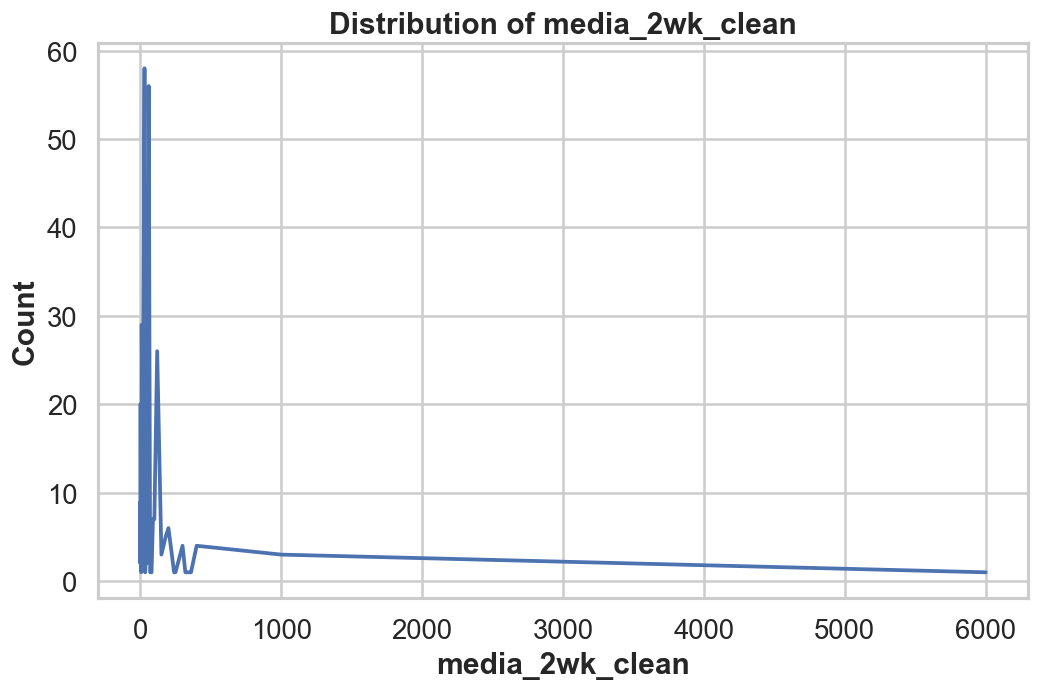

In [14]:
[c for c in df.columns if c.startswith("media_2wk")]
#df["media_2wk_clean"].value_counts().sort_index().plot()

fig, ax = plt.subplots(figsize=(10, 6))

(
    df["media_2wk_clean"]
    .value_counts()
    .sort_index()
    .plot(ax=ax)
)

ax.set_title("Distribution of media_2wk_clean")
ax.set_xlabel("media_2wk_clean")
ax.set_ylabel("Count")

save_plot(
    fig=fig,
    filename="media_2wk_distribution",
    output_dir=OUTPUT_DIR,
    log_path=LOG_PATH
)

plt.show()

In [15]:
# column: media_reserv
## Step 1 — run parser
df, change_df, review_path = run_parser_pre_manual(
    df,
    column="media_reserv",
    parser_func=parse_time_to_minutes,
    config=TIME_MINUTES_CONFIG,
    output_dir=OUTPUT_DIR,
    log_path=LOG_PATH
)

# 👉 manually edit the file here

[2026-06-07 16:25:02] Running parser for column: media_reserv
[2026-06-07 16:25:02] Manual review file exported: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\media_reserv_manual_review.csv
STOP! go over the file in: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\media_reserv_manual_review.csv
See if you want to make manual adjustments. If so, make them, save and exit and come back here to run the next block


In [16]:
# column: media_reserv
## Step 2 — apply manual fixes
df, full_log = apply_manual_corrections(
    df,
    column="media_reserv",
    change_df=change_df,
    review_path=review_path,
    output_dir=OUTPUT_DIR,
    config=TIME_MINUTES_CONFIG,
    log_path=LOG_PATH
)

# mark features for removal
feature_removal_registry.append({
    "columns": ["media_2wk","media_reserv"],
    "removal_reason": "parsed_columns_unparsed",
    "removal_stage": "parsed_columns_txt2numeric"
})

[2026-06-07 16:25:02] Applying manual corrections for column: media_reserv
[2026-06-07 16:25:02] media_reserv_clean dtype enforced as Int64
[2026-06-07 16:25:02] media_reserv_raw dropped from final dataframe (original column retained)
[2026-06-07 16:25:02] Total automatic changes: 29
[2026-06-07 16:25:02] Total manual changes: 26
[2026-06-07 16:25:02] Full change log saved: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\media_reserv_full_change_log.csv


[2026-06-07 16:25:03] Plot saved: media_reserve_distribution.png
Saved plot: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\media_reserve_distribution.png


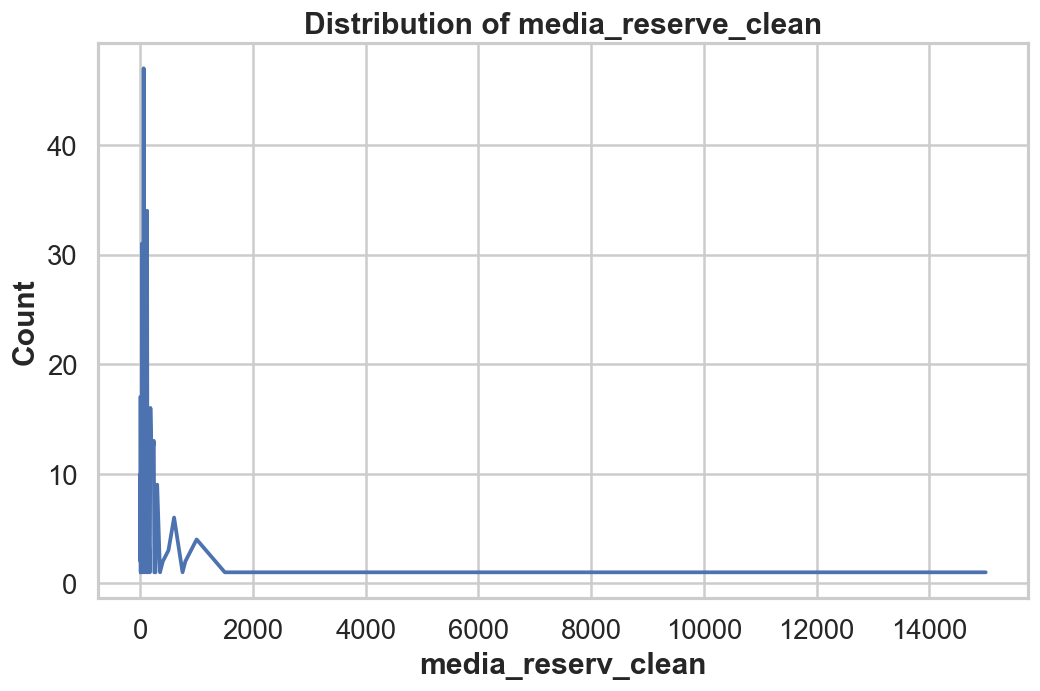

In [17]:
#[c for c in df.columns if c.startswith("media_reserv")]
#df["media_reserv_clean"].value_counts().sort_index().plot()

fig, ax = plt.subplots(figsize=(10, 6))

(
    df["media_reserv_clean"]
    .value_counts()
    .sort_index()
    .plot(ax=ax)
)

ax.set_title("Distribution of media_reserve_clean")
ax.set_xlabel("media_reserv_clean")
ax.set_ylabel("Count")

save_plot(
    fig=fig,
    filename="media_reserve_distribution",
    output_dir=OUTPUT_DIR,
    log_path=LOG_PATH
)

plt.show()

[2026-06-07 16:25:03] Starting media comparison analysis.
[2026-06-07 16:25:03] Numeric cleaning complete.
[2026-06-07 16:25:03] Log transformation complete.
[2026-06-07 16:25:03] Plot saved: media_distribution.png
Saved plot: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\media_distribution.png


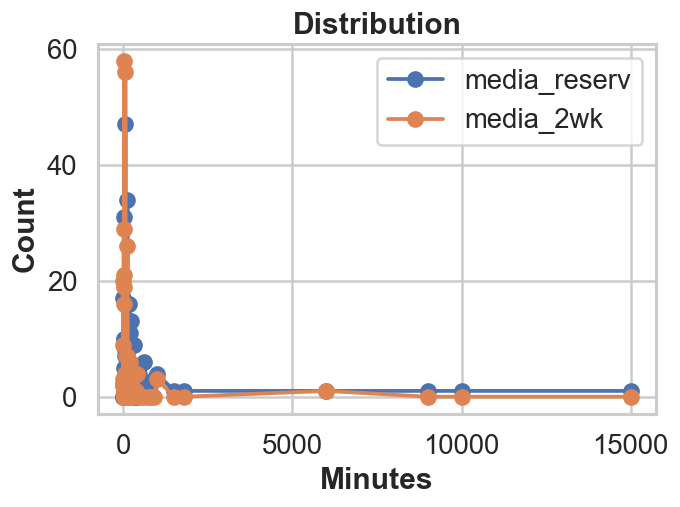

[2026-06-07 16:25:03] Distribution comparison plot complete.
[2026-06-07 16:25:03] Plot saved: media_scatter_log.png
Saved plot: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\media_scatter_log.png


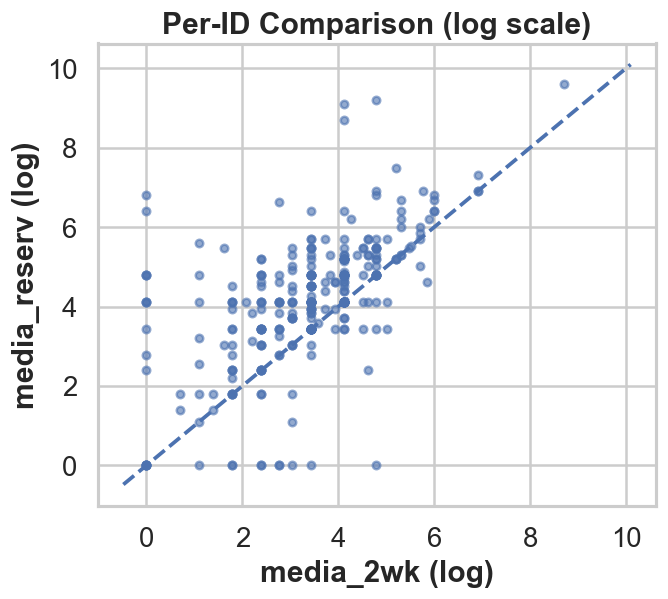

[2026-06-07 16:25:03] Scatter comparison plot complete.
[2026-06-07 16:25:04] Plot saved: media_per_id_log_complete_cases.png
Saved plot: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\media_per_id_log_complete_cases.png


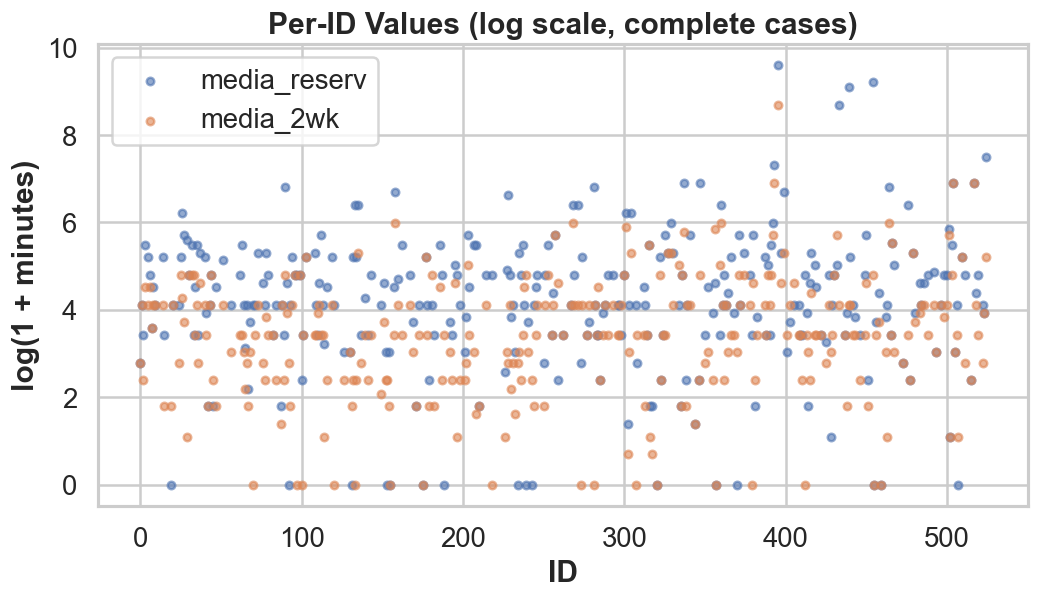

[2026-06-07 16:25:04] Media comparison analysis complete.


In [18]:
# ============================================
# Media variables comparison analysis
# ============================================

write_log("Starting media comparison analysis.", LOG_PATH)

# ----------------------------------
# Step 1 — Clean numeric columns
# ----------------------------------
df["media_2wk_clean"] = (pd.to_numeric(df["media_2wk_clean"], errors="coerce").astype(float))
df["media_reserv_clean"] = (pd.to_numeric(df["media_reserv_clean"], errors="coerce").astype(float))
write_log("Numeric cleaning complete.", LOG_PATH)

# ----------------------------------
# Step 2 — Log transform (safe for zeros)
# ----------------------------------

df["media_2wk_log"] = np.log1p(df["media_2wk_clean"])
df["media_reserv_log"] = np.log1p(df["media_reserv_clean"])
write_log("Log transformation complete.", LOG_PATH)

# ----------------------------------
# Step 3 — Distribution comparison
# ----------------------------------

vc_reserv = (df["media_reserv_clean"].value_counts().sort_index())
vc_2wk = (df["media_2wk_clean"].value_counts().sort_index())
all_index = sorted(set(vc_reserv.index).union(set(vc_2wk.index)))

vc_reserv = vc_reserv.reindex(all_index, fill_value=0)
vc_2wk = vc_2wk.reindex(all_index, fill_value=0)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(vc_reserv.index, vc_reserv.values, marker="o", label="media_reserv")
ax.plot(vc_2wk.index, vc_2wk.values, marker="o", label="media_2wk")
ax.set_title("Distribution")
ax.set_xlabel("Minutes")
ax.set_ylabel("Count")
ax.legend()
ax.grid(True)

save_plot(fig=fig, filename="media_distribution", output_dir=OUTPUT_DIR, log_path=LOG_PATH)

plt.show()
plt.close(fig)
write_log("Distribution comparison plot complete.", LOG_PATH)

# ----------------------------------
# Step 4 — Scatter comparison
# ----------------------------------
plot_df = (df[["media_2wk_log", "media_reserv_log"]].dropna())
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(plot_df["media_2wk_log"], plot_df["media_reserv_log"], alpha=0.6, s=20)

# diagonal reference
lims = [np.min([ax.get_xlim()[0], ax.get_ylim()[0]]), np.max([ax.get_xlim()[1], ax.get_ylim()[1]])]
ax.plot(lims, lims, linestyle="--")
ax.set_xlabel("media_2wk (log)")
ax.set_ylabel("media_reserv (log)")
ax.set_title("Per-ID Comparison (log scale)")
ax.grid(True)
save_plot(fig=fig, filename="media_scatter_log", output_dir=OUTPUT_DIR, log_path=LOG_PATH)

plt.show()
plt.close(fig)
write_log("Scatter comparison plot complete.", LOG_PATH)

# ----------------------------------
# Step 5 — Per-ID values
# ----------------------------------
x = df.index  # or df["record_id"]
mask_both = (df["media_reserv_clean"].notna() & df["media_2wk_clean"].notna())
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(x[mask_both], df.loc[mask_both, "media_reserv_log"], label="media_reserv", alpha=0.6, s=20)
ax.scatter(x[mask_both], df.loc[mask_both, "media_2wk_log"], label="media_2wk", alpha=0.6, s=20)
ax.set_xlabel("ID")
ax.set_ylabel("log(1 + minutes)")
ax.set_title("Per-ID Values (log scale, complete cases)")
ax.legend()
ax.grid(True)

save_plot(fig=fig, filename="media_per_id_log_complete_cases", output_dir=OUTPUT_DIR, log_path=LOG_PATH)

plt.show()
plt.close(fig)
write_log("Media comparison analysis complete.", LOG_PATH)

In [19]:
# column: children_2
## Step 1 — run parser
df, change_df, review_path = run_parser_pre_manual(
    df,
    column="children_2",
    parser_func=parse_time_to_years,
    config=TIME_YEARS_CONFIG,
    output_dir=OUTPUT_DIR,
    log_path=LOG_PATH
)

# 👉 manually edit the file here

[2026-06-07 16:25:04] Running parser for column: children_2
[2026-06-07 16:25:04] Manual review file exported: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\children_2_manual_review.csv
STOP! go over the file in: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\children_2_manual_review.csv
See if you want to make manual adjustments. If so, make them, save and exit and come back here to run the next block


In [20]:
# column: children_2
## Step 2 — apply manual fixes
df, full_log = apply_manual_corrections(
    df,
    column="children_2",
    change_df=change_df,
    review_path=review_path,
    output_dir=OUTPUT_DIR,
    config=TIME_YEARS_CONFIG,
    log_path=LOG_PATH
)

[2026-06-07 16:25:06] Applying manual corrections for column: children_2
[2026-06-07 16:25:06] children_2_clean dtype enforced as Int64
[2026-06-07 16:25:06] children_2_raw dropped from final dataframe (original column retained)
[2026-06-07 16:25:06] Total automatic changes: 5
[2026-06-07 16:25:06] Total manual changes: 0
[2026-06-07 16:25:06] Full change log saved: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\children_2_full_change_log.csv


[2026-06-07 16:25:06] Plot saved: age_of_youngest_distribution.png
Saved plot: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\age_of_youngest_distribution.png


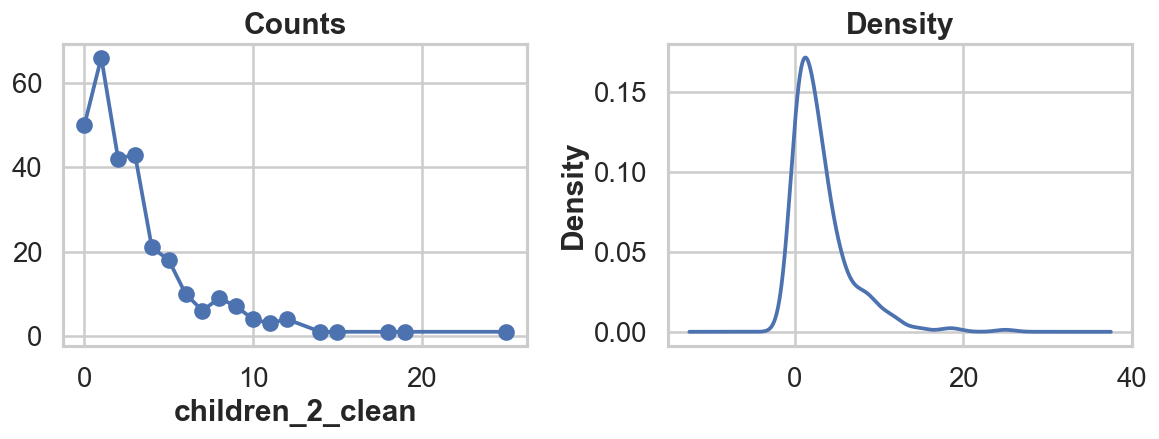

In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

df["children_2_clean"].value_counts().sort_index().plot(marker="o", ax=axes[0])
axes[0].set_title("Counts")

df["children_2_clean"].plot(kind="kde", ax=axes[1])
axes[1].set_title("Density")
plt.tight_layout()

save_plot(fig, "age_of_youngest_distribution", OUTPUT_DIR, LOG_PATH)
#plt.savefig(OUTPUT_DIR / "age_of_youngest_distribution.png", dpi=300)
plt.show()
plt.close()

In [22]:
# column: wk_delv1
## Step 1 — run parser
df, change_df, review_path = run_parser_pre_manual(
    df,
    column="wk_delv1",
    parser_func=parse_time_to_weeks,
    config=TIME_WEEKS_CONFIG,
    output_dir=OUTPUT_DIR,
    log_path=LOG_PATH
)

# 👉 manually edit the file here

[2026-06-07 16:25:08] Running parser for column: wk_delv1
[2026-06-07 16:25:08] Manual review file exported: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\wk_delv1_manual_review.csv
STOP! go over the file in: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\wk_delv1_manual_review.csv
See if you want to make manual adjustments. If so, make them, save and exit and come back here to run the next block


In [23]:
# column: wk_delv1
## Step 2 — apply manual fixes
df, full_log = apply_manual_corrections(
    df,
    column="wk_delv1",
    change_df=change_df,
    review_path=review_path,
    output_dir=OUTPUT_DIR,
    config=TIME_WEEKS_CONFIG,
    log_path=LOG_PATH
)

[2026-06-07 16:25:08] Applying manual corrections for column: wk_delv1
[2026-06-07 16:25:08] wk_delv1_clean dtype enforced as Int64
[2026-06-07 16:25:08] wk_delv1_raw dropped from final dataframe (original column retained)
[2026-06-07 16:25:08] Total automatic changes: 5
[2026-06-07 16:25:08] Total manual changes: 0
[2026-06-07 16:25:08] Full change log saved: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\wk_delv1_full_change_log.csv


[2026-06-07 16:25:10] Plot saved: week_delv1_distribution.png
Saved plot: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\week_delv1_distribution.png


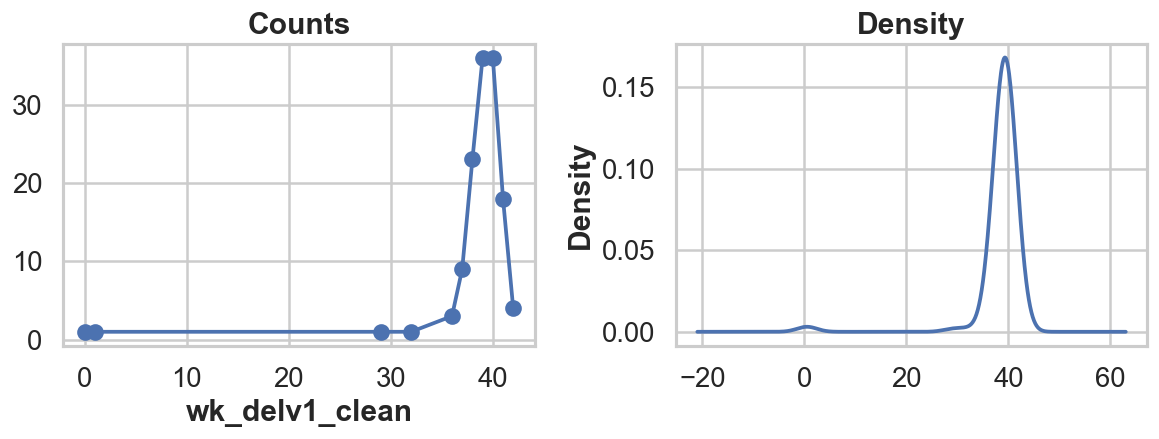

In [24]:
import matplotlib.pyplot as plt
import pandas as pd

# Keep only non-missing values
plot_data = df["wk_delv1_clean"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Counts
plot_data.value_counts().sort_index().plot(marker="o", ax=axes[0])
axes[0].set_title("Counts")

# Density
plot_data.plot(kind="kde", ax=axes[1])
axes[1].set_title("Density")

plt.tight_layout()
#plt.savefig(OUTPUT_DIR / "week_delv1_distribution.png", dpi=300)
save_plot(fig, "week_delv1_distribution", OUTPUT_DIR, LOG_PATH)
plt.show()
plt.close()

In [25]:
# column: wk_delv2
## Step 1 — run parser
df, change_df, review_path = run_parser_pre_manual(
    df,
    column="wk_delv2",
    parser_func=parse_time_to_weeks,
    config=TIME_WEEKS_CONFIG,
    output_dir=OUTPUT_DIR,
    log_path=LOG_PATH
)

# 👉 manually edit the file here

[2026-06-07 16:25:10] Running parser for column: wk_delv2
[2026-06-07 16:25:10] Manual review file exported: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\wk_delv2_manual_review.csv
STOP! go over the file in: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\wk_delv2_manual_review.csv
See if you want to make manual adjustments. If so, make them, save and exit and come back here to run the next block


In [26]:
# column: wk_delv2
## Step 2 — apply manual fixes
df, full_log = apply_manual_corrections(
    df,
    column="wk_delv2",
    change_df=change_df,
    review_path=review_path,
    output_dir=OUTPUT_DIR,
    config=TIME_WEEKS_CONFIG,
    log_path=LOG_PATH
)

[2026-06-07 16:25:13] Applying manual corrections for column: wk_delv2
[2026-06-07 16:25:13] wk_delv2_clean dtype enforced as Int64
[2026-06-07 16:25:13] wk_delv2_raw dropped from final dataframe (original column retained)
[2026-06-07 16:25:13] Total automatic changes: 1
[2026-06-07 16:25:13] Total manual changes: 0
[2026-06-07 16:25:13] Full change log saved: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\wk_delv2_full_change_log.csv


[2026-06-07 16:25:15] Plot saved: week_delv2_distribution.png
Saved plot: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\week_delv2_distribution.png


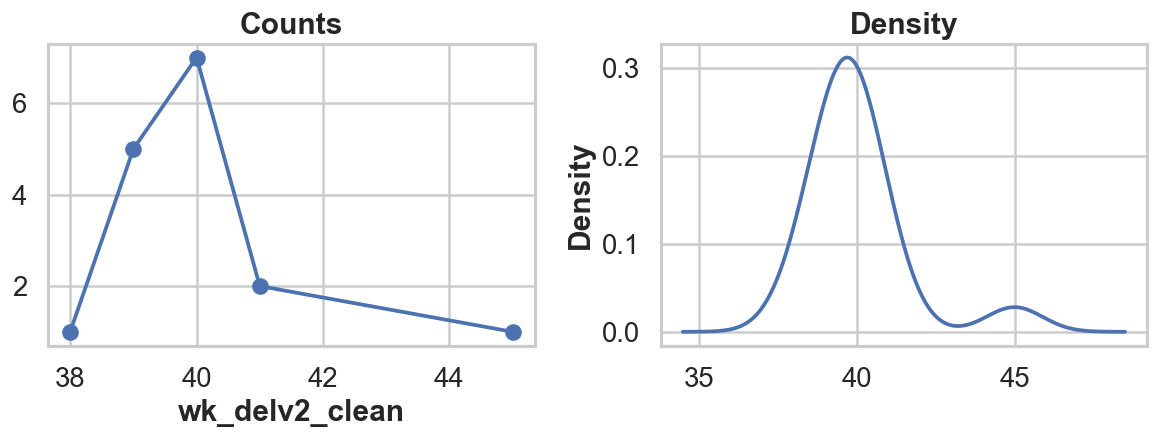

In [27]:
import matplotlib.pyplot as plt
import pandas as pd

# Keep only non-missing values
plot_data = df["wk_delv2_clean"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Counts
plot_data.value_counts().sort_index().plot(marker="o", ax=axes[0])
axes[0].set_title("Counts")

# Density
plot_data.plot(kind="kde", ax=axes[1])
axes[1].set_title("Density")

plt.tight_layout()
#plt.savefig(OUTPUT_DIR / "week_delv2_distribution.png", dpi=300)
save_plot(fig, "week_delv2_distribution", OUTPUT_DIR, LOG_PATH)
plt.show()
plt.close()

In [28]:
# mark features for removal
feature_removal_registry.append({
    "columns": ["media_2wk","media_reserv","children_2","wk_delv1","wk_delv2"],
    "removal_reason": "parsed_columns_unparsed",
    "removal_stage": "parsed_columns_txt2numeric"
})

In [29]:
# ================================================================================================================
# 9. Manual Participant Clean-up: detect "fake" or incomplete participants, based on suspicious response patterns
# ================================================================================================================
# ============================================
# QC STEP A — Identify continuous questionnaire variables automatically
# ============================================
write_log("Selecting continuous variables for QC metrics.", LOG_PATH)

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

existing_technical_columns = [
    col for col in technical_columns
    if col in df.columns
]

EXCLUDE_COLS = (
    ["record_id"]
    + existing_technical_columns
    + [col for col in df.columns if col.startswith("qc_")] # this is a small patch in case of going back and forth in notebook
)

continuous_cols = [
    col for col in numeric_cols
    if col not in EXCLUDE_COLS
    and df[col].nunique(dropna=True) > 2
    and df[col].std(skipna=True) > 0
]

write_log(f"Continuous variables identified: {len(continuous_cols)}", LOG_PATH)

from scipy.stats import entropy

write_log("Computing response entropy.", LOG_PATH)

bad_cols = [
    col for col in continuous_cols
    if not pd.api.types.is_numeric_dtype(df[col])
]

write_log(f"Non-numeric columns inside continuous_cols: {bad_cols}", LOG_PATH)


df["qc_response_entropy"] = df[continuous_cols].apply(
    compute_entropy,
    axis=1
)

write_log("Computing long string index.", LOG_PATH)
write_log("Checking suspicious missing codes.", LOG_PATH)
SUSPICIOUS_VALUES = ["", " ", "NA", "N/A", "na", "n/a", 99, 999, -9, -99]
df["qc_suspicious_code"] = df.isin(SUSPICIOUS_VALUES).any(axis=1)

# Age range validation

write_log("Validating age range.", LOG_PATH)

AGE_MIN = 18
AGE_MAX = 60

if "age_v2" not in df.columns:
    write_log("WARNING: age column not found. Skipping age validation.", LOG_PATH)
    df["qc_age_out_of_range"] = False

else:
    df["qc_age_out_of_range"] = (
        (df["age_v2"].notna()) &
        (
            (df["age_v2"] < AGE_MIN) |
            (df["age_v2"] > AGE_MAX)
        )
    )

    n_bad_age = df["qc_age_out_of_range"].sum()
    write_log(f"Participants with age outside valid range: {n_bad_age}", LOG_PATH)


# num_reserv range validation
write_log("Validating num_reserv range.", LOG_PATH)

NUM_RESERV_MIN = 1
NUM_RESERV_MAX = 20

if "num_reserv" not in df.columns:
    write_log("WARNING: num_reserv column not found. Skipping validation.", LOG_PATH)
    df["qc_num_reserv_out_of_range"] = False

else:
    df["qc_num_reserv_out_of_range"] = (
        (df["num_reserv"].notna()) &
        (
            (df["num_reserv"] < NUM_RESERV_MIN) |
            (df["num_reserv"] >= NUM_RESERV_MAX)
        )
    )

    n_bad = df["qc_num_reserv_out_of_range"].sum()
    write_log(f"Participants with num_reserv outside valid range: {n_bad}", LOG_PATH)

# reserv_days range validation
write_log("Validating reserv_days range.", LOG_PATH)

if "reserv_days" not in df.columns:
    write_log("WARNING: reserv_days column not found. Skipping validation.", LOG_PATH)
    df["qc_reserv_days_out_of_range"] = False

else:
    df["qc_reserv_days_out_of_range"] = (
        (df["reserv_days"].notna()) &
        (df["reserv_days"] <= 0)
    )

    n_bad = df["qc_reserv_days_out_of_range"].sum()
    write_log(f"Participants with reserv_days outside valid range: {n_bad}", LOG_PATH)

# Attestation completion check
write_log("Validating attestation completion.", LOG_PATH)

if "attestation_timestamp" not in df.columns:
    write_log("WARNING: attestation_timestamp column not found.", LOG_PATH)
    df["qc_attestation_incomplete"] = False

else:
    df["qc_attestation_incomplete"] = (
        df["attestation_timestamp"].astype(str).str.strip().str.lower()
        == "[not completed]"
    )

    n_bad = df["qc_attestation_incomplete"].sum()
    write_log(f"Participants with incomplete attestation: {n_bad}", LOG_PATH)

# Signature blank check
write_log("Validating signature field.", LOG_PATH)

if "signature" not in df.columns:
    write_log("WARNING: signature column not found.", LOG_PATH)
    df["qc_signature_blank"] = False

else:
    df["qc_signature_blank"] = (
        df["signature"].isna() |
        (df["signature"].astype(str).str.strip() == "")
    )

    n_bad = df["qc_signature_blank"].sum()
    write_log(f"Participants with blank signature: {n_bad}", LOG_PATH)

[2026-06-07 16:25:17] Selecting continuous variables for QC metrics.
[2026-06-07 16:25:17] Continuous variables identified: 147
[2026-06-07 16:25:17] Computing response entropy.
[2026-06-07 16:25:17] Non-numeric columns inside continuous_cols: []
[2026-06-07 16:25:17] Computing long string index.
[2026-06-07 16:25:17] Checking suspicious missing codes.
[2026-06-07 16:25:17] Validating age range.
[2026-06-07 16:25:17] Participants with age outside valid range: 3
[2026-06-07 16:25:17] Validating num_reserv range.
[2026-06-07 16:25:17] Participants with num_reserv outside valid range: 5
[2026-06-07 16:25:17] Validating reserv_days range.
[2026-06-07 16:25:17] Participants with reserv_days outside valid range: 1
[2026-06-07 16:25:17] Validating attestation completion.
[2026-06-07 16:25:17] Participants with incomplete attestation: 112
[2026-06-07 16:25:17] Validating signature field.
[2026-06-07 16:25:17] WARNING: signature column not found.


In [30]:
# ============================================
# QC STEP B — Build unified participant flag table
# ============================================

write_log("Building participant flag table.", LOG_PATH)

flag_records = []

entropy_threshold = df["qc_response_entropy"].quantile(0.03)
missing_threshold = 70

for idx, row in df.iterrows():
    record_id = row["record_id"]
    reasons = []
    details = []

    # Percent of Missing Values
    if row["missing_percent"] > missing_threshold:
        reasons.append("high_percent_missing")
        details.append(f"missing_percent={row['missing_percent']:.4f}")

    # Response entropy
    if row["qc_response_entropy"] <= entropy_threshold:
        reasons.append("low_response_entropy")
        details.append(f"entropy={row['qc_response_entropy']:.4f}")

    # Suspicious missing codes
    if row["qc_suspicious_code"]:
        reasons.append("contains_suspicious_missing_code")
        bad_cols = df.columns[df.loc[idx].isin(SUSPICIOUS_VALUES)]

        for col in bad_cols:
            details.append(f"{col}={row[col]}")

    # Age validation
    if row["qc_age_out_of_range"]:
        reasons.append("age_out_of_valid_range")
        details.append(f"age={row['age_v2']}")

    # num_reserv validation
    if row["qc_num_reserv_out_of_range"]:
        reasons.append("num_reserv_out_of_valid_range")
        details.append(f"num_reserv={row['num_reserv']}")

    # reserv_days validation
    if row["qc_reserv_days_out_of_range"]:
        reasons.append("reserv_days_out_of_valid_range")
        details.append(f"reserv_days={row['reserv_days']}")

        # Attestation incomplete
    if row["qc_attestation_incomplete"]:
        reasons.append("attestation_not_completed")
        details.append("attestation_timestamp=[not completed]")

        # Signature blank
    if row["qc_signature_blank"]:
        reasons.append("signature_blank")
        details.append("signature=blank_or_missing")

        # Inclusion / exclusion validity check (both inclusion and exclusion must equal 1)
    invalid_flags = []
    for col in ["inclusion", "exclusion"]:
        if row[col] != 1:
            invalid_flags.append(f"{col}={row[col]}")

        if len(invalid_flags) > 0:
            reasons.append("inclusion/exclusion_not_1")
            details.append("; ".join(invalid_flags))

        # Duplicate participant check
    if record_id in duplicate_reason_map:

        duplicate_reason = duplicate_reason_map[record_id]

        reasons.append("duplicate_participant")

        details.append(
            f"duplicate_reason={duplicate_reason}"
        )
    
    if len(reasons) > 0:    
        flag_records.append({
            "record_id": record_id,
            "flag_reason": "; ".join(reasons),
            "flag_details": "; ".join(details),
            "remove": False
        })


flag_df = pd.DataFrame(flag_records)
write_log(f"Participants flagged: {len(flag_df)}", LOG_PATH)

[2026-06-07 16:25:17] Building participant flag table.
[2026-06-07 16:25:17] Participants flagged: 245


In [31]:
# ============================================
# QC STEP C — Export review file (human-optimized layout)
# ============================================

write_log("Preparing QC review file with optimized column layout.", LOG_PATH)
REVIEW_PATH = OUTPUT_DIR / "QC_review_file.xlsx"

# --------------------------------------------
# Merge flags into original dataframe
# --------------------------------------------
review_export = df.merge(
    flag_df,
    on="record_id",
    how="left"
)

# --------------------------------------------
# Ensure review columns exist and are clean
# --------------------------------------------
review_export["remove"] = review_export["remove"].fillna(False)
review_export["flag_reason"] = review_export["flag_reason"].fillna("")
review_export["flag_details"] = review_export["flag_details"].fillna("")

# --------------------------------------------
# Reorder columns for human review
# --------------------------------------------
review_columns = [
    "record_id",
    "remove",
    "flag_reason",
    "flag_details"
]

original_columns = [
    col for col in review_export.columns
    if col not in review_columns
]

review_export = review_export[
    review_columns + original_columns
]

# --------------------------------------------
# Export to Excel
# --------------------------------------------
review_export.to_excel(
    REVIEW_PATH,
    index=False,
    engine="openpyxl"
)

from openpyxl import load_workbook

wb = load_workbook(REVIEW_PATH)
ws = wb.active

# freeze first row and review columns
ws.freeze_panes = "E2"  
wb.save(REVIEW_PATH)

write_log(f"QC review file exported: {REVIEW_PATH}", LOG_PATH)
write_log(f"Total participants in review file: {len(review_export)}", LOG_PATH)
write_log(f"Flagged participants: {(review_export['flag_reason'] != '').sum()}", LOG_PATH)
write_log("Pipeline paused for manual review.", LOG_PATH)

[2026-06-07 16:25:18] Preparing QC review file with optimized column layout.
[2026-06-07 16:25:22] QC review file exported: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\QC_review_file.xlsx
[2026-06-07 16:25:22] Total participants in review file: 526
[2026-06-07 16:25:22] Flagged participants: 245
[2026-06-07 16:25:22] Pipeline paused for manual review.


!!!!!!!!!! STOP!!!!!!!!!!
USER MANUAL STEP (outside notebook)

User opens Excel and:

• fixes values where needed
• sets remove = TRUE for participants to exclude
• saves file (with original name)

In [32]:
# ============================================
# QC STEP D — Re-import reviewed file
# ============================================
write_log("Loading reviewed QC file.", LOG_PATH)
reviewed_df = pd.read_excel(REVIEW_PATH)

remove_ids = reviewed_df.loc[
    reviewed_df["remove"] == True,
    "record_id"
]

write_log(f"Participants marked for removal: {len(remove_ids)}", LOG_PATH)

[2026-06-07 16:25:22] Loading reviewed QC file.
[2026-06-07 16:25:23] Participants marked for removal: 0


In [33]:
# ========================================
# Log removal decisions
# ========================================
REMOVAL_LOG_PATH = OUTPUT_DIR / f"QC_removal_log_{TIMESTAMP}.csv"
reviewed_df.loc[
    reviewed_df["remove"] == True,
    ["record_id", "flag_reason", "flag_details"]
].to_csv(
    REMOVAL_LOG_PATH,
    index=False
)

write_log(f"Removal log saved: {REMOVAL_LOG_PATH}", LOG_PATH)

# apply removals
original_n = len(df)

df_clean = df[
    ~df["record_id"].isin(remove_ids)
].copy()

write_log(f"Original sample size: {original_n}", LOG_PATH)
write_log(f"Final sample size: {len(df_clean)}", LOG_PATH)
write_log(f"Participants removed: {original_n - len(df_clean)}", LOG_PATH)

# restore clean structure
QC_COLUMNS = [
    "qc_response_entropy",
    "qc_suspicious_code",
    "qc_age_out_of_range",
    "qc_num_reserv_out_of_range",
    "qc_reserv_days_out_of_range",
    "qc_attestation_incomplete",
    "qc_signature_blank",
    "missing_count",
    "missing_percent",
    "days_since_source",
    "qc_days_since_missing",
    "qc_days_since_negative",
    "qc_days_since_imputed"
]

OTHER_HOUSEKEEPING_COLUMNS = [
    "redcap_event_name",
    "receive_communication",
    "inclusion",
    "exclusion",
    "agree",
    "interview_consent",
    "contact_6mn",
    "recruit",
    "recruit_other",
    "payment_type"
]

# mark features for removal
feature_removal_registry.append({
    "columns": QC_COLUMNS,
    "removal_reason": "QC_columns",
    "removal_stage": "participant_removal"
})

# mark features for removal
feature_removal_registry.append({
    "columns": OTHER_HOUSEKEEPING_COLUMNS,
    "removal_reason": "housekeeping_features",
    "removal_stage": "dataset_cleanup"
})

'''
df_clean.drop(
    columns=[c for c in QC_COLUMNS if c in df_clean.columns],
    inplace=True
)'''

[2026-06-07 16:25:23] Removal log saved: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\QC_removal_log_20260607_1624.csv
[2026-06-07 16:25:23] Original sample size: 526
[2026-06-07 16:25:23] Final sample size: 526
[2026-06-07 16:25:23] Participants removed: 0


'\ndf_clean.drop(\n    columns=[c for c in QC_COLUMNS if c in df_clean.columns],\n    inplace=True\n)'

In [34]:
# ========================================
# Apply manual review changes and log them
# ========================================

MANUAL_CHANGE_LOG_PATH = OUTPUT_DIR / f"QC_manual_change_log_{TIMESTAMP}.csv"

manual_change_records = []

exclude_cols = ["remove", "record_id"]

# Use record_id as lookup index
reviewed_lookup = reviewed_df.set_index("record_id")
df_clean_lookup = df_clean.set_index("record_id")

shared_ids = reviewed_lookup.index.intersection(df_clean_lookup.index)

for record_id in shared_ids:

    reviewed_row = reviewed_lookup.loc[record_id]
    df_row = df_clean_lookup.loc[record_id]

    for col in reviewed_df.columns:

        if col in exclude_cols:
            continue

        if col not in df_clean.columns:
            continue

        original_value = df_row[col]
        reviewed_value = reviewed_row[col]

        # Compare while handling NaNs
        if pd.isna(original_value) and pd.isna(reviewed_value):
            values_different = False
        
        elif pd.isna(original_value) or pd.isna(reviewed_value):
            values_different = True
        
        elif isinstance(original_value, (float, np.floating)):
            values_different = round(original_value, 3) != round(reviewed_value, 3)
        
        else:
            values_different = original_value != reviewed_value
    
        if values_different:

            manual_change_records.append({
                "record_id": record_id,
                "column": col,
                "original_value": original_value,
                "reviewed_value": reviewed_value
            })

            # Apply update directly using record_id
            df_clean.loc[
                df_clean["record_id"] == record_id,
                col
            ] = reviewed_value

# Save manual change log
manual_change_log = pd.DataFrame(manual_change_records)

manual_change_log.to_csv(
    MANUAL_CHANGE_LOG_PATH,
    index=False
)

write_log(
    f"Manual change log saved: {MANUAL_CHANGE_LOG_PATH}",
    LOG_PATH
)

[2026-06-07 16:25:24] Manual change log saved: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\QC_manual_change_log_20260607_1624.csv


In [35]:
# remove all of the marked features
for removal_job in feature_removal_registry:

    (df_clean, removed_feature_values_df, removal_log_df) = audit_and_remove_features(
        dataframe=df_clean,
        columns=removal_job["columns"],
        removal_reason=removal_job["removal_reason"],
        log_path=LOG_PATH,
        removed_feature_values_df=removed_feature_values_df,
        removal_log_df=removal_log_df,
        feature_removal_audit_path=FEATURE_REMOVAL_AUDIT_PATH,
        override_main_df=True,
        removal_stage=removal_job["removal_stage"]
    )

[2026-06-07 16:25:24] Removing features from returned dataframe copy.
[2026-06-07 16:25:24] Exporting feature removal audit workbook.
[2026-06-07 16:25:24] Audited 1 features.
[2026-06-07 16:25:24] Features:
[2026-06-07 16:25:24] days_since_source
[2026-06-07 16:25:24] Removal reason: temporary feature
[2026-06-07 16:25:24] Removal stage: days_since_oct7_calculation
[2026-06-07 16:25:24] override_main_df = True
[2026-06-07 16:25:24] IMPORTANT:
[2026-06-07 16:25:24] Original dataframe was NOT modified in-place.
[2026-06-07 16:25:24] Only the returned dataframe copy was altered.
[2026-06-07 16:25:24] Audit workbook updated:
[2026-06-07 16:25:24] C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\feature_removal_audit.xlsx
[2026-06-07 16:25:24] Removing features from returned dataframe copy.
[2026-06-07 16:25:24] Exporting feature removal audit workbook.
[2026-06-07 16:25:25] Audited 61 features.
[2026-06-07 16:25:25] Features:


In [36]:
# Export frozen clean dataset
FINAL_PATH = OUTPUT_DIR / f"analysis_ready_dataset_{TIMESTAMP}.xlsx"

df_clean.to_excel(
    FINAL_PATH,
    index=False
)

write_log(f"Final clean dataset saved: {FINAL_PATH}", LOG_PATH)

[2026-06-07 16:25:37] Final clean dataset saved: C:\Users\NoaBarLiss\Documents\02.Personal_development\invisible_warriors\code\00.Data_prep\outputs\202606071624\analysis_ready_dataset_20260607_1624.xlsx
